In [1]:
import json
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.covariance import LedoitWolf

from MirrorFeatureExtractor.baseline import (
    extract_photometric,
    new_extract_edge_features,
    proces_one_img,
    robust_z
)
from MirrorExtractor.simple_mirror_extractor import SimpleMirrorExtractor

from DetectionMetrics.detection_metrics import DetectionMetrics, compute_metrics

from tools import show_img, mark_mirrors_on_img

In [2]:
# test_img_json_path =  "/media/pgliwny/ADATA HD3304/Computer_vision_for_MAGIC/data/img_with_annomarly.json"
test_img_json_path = "/home/pgliwny/Praca/Computer_vision_for_MAGIC/data/annotations/img_annomarly_05.json"
with open(test_img_json_path) as f:
    json_metadata_list = json.load(f)

print(json_metadata_list[0])
print(len(json_metadata_list))

{'file': '20240505_1800_la.jpg', 'marked_mirrors': [152, 190]}
17


In [15]:
BASELINE_OUT_FILE = "/home/pgliwny/Praca/Computer_vision_for_MAGIC/scripts/scripts_for_baseline/output/out_baseline_webcam.npz"
CALIB_FILE = "/home/pgliwny/Praca/Computer_vision_for_MAGIC/data/calibration/points_WebCam.json"
IMG_DIR_PATH = Path("/home/pgliwny/Praca/Computer_vision_for_MAGIC/data/webcam/2024/05/good")
mirror_extractor = SimpleMirrorExtractor(CALIB_FILE)

# Load baseline model
b = np.load(BASELINE_OUT_FILE, allow_pickle=False)
lw = LedoitWolf()
lw.covariance_ = b["covariance"]
lw.location_ = b["location"]
lw.precision_ = np.linalg.pinv(b["covariance"])
print(b["threshold"])

7.645782272853682


In [22]:
def calc_metrics(obj_list, lw, baseline, threshold):
    tp_sum = 0
    fp_sum = 0
    fn_sum = 0
    for i, obj in enumerate(obj_list):
        file_name = obj['file']
        img_path = IMG_DIR_PATH / file_name
        X_new = proces_one_img(img_path, mirror_extractor)
        R_new = robust_z(X_new[None, ...], axis=1)[0]
        Z_new = R_new - baseline["mu"]
        d2 = lw.mahalanobis(Z_new)
        score = d2 / baseline["d2_med"]
        outliers_mirrors = np.where(score > threshold)[0]

        ground_truth = obj["marked_mirrors"]
        metrics = compute_metrics(outliers_mirrors, ground_truth)

        tp_sum += metrics.tp
        fp_sum += metrics.fp
        fn_sum += metrics.fn

    precision = tp_sum / (tp_sum + fp_sum)
    recall = tp_sum / (tp_sum + fn_sum)
    print(f"True positive: %d: {tp_sum}")
    print(f"False positive: %d: {fp_sum}")
    print(f"False negative: %d: {fn_sum}")
    print("Summary precision: %.3f", precision)
    print("Summary recall: %.3f", recall)
    return precision, recall


In [25]:
precision_list, recall_list = [], []
threshold_list = [5, 8, 11, 14, 17, 20, 23, 26]
for thr in threshold_list:
    precision, recall = calc_metrics(json_metadata_list, lw, b, thr)
    precision_list.append(precision)
    recall_list.append(recall)

True positive: %d: 129
False positive: %d: 768
False negative: %d: 12
Summary precision: %.3f 0.14381270903010032
Summary recall: %.3f 0.9148936170212766
True positive: %d: 111
False positive: %d: 424
False negative: %d: 30
Summary precision: %.3f 0.20747663551401868
Summary recall: %.3f 0.7872340425531915
True positive: %d: 100
False positive: %d: 276
False negative: %d: 41
Summary precision: %.3f 0.26595744680851063
Summary recall: %.3f 0.7092198581560284
True positive: %d: 88
False positive: %d: 191
False negative: %d: 53
Summary precision: %.3f 0.3154121863799283
Summary recall: %.3f 0.624113475177305
True positive: %d: 77
False positive: %d: 142
False negative: %d: 64
Summary precision: %.3f 0.3515981735159817
Summary recall: %.3f 0.5460992907801419
True positive: %d: 70
False positive: %d: 112
False negative: %d: 71
Summary precision: %.3f 0.38461538461538464
Summary recall: %.3f 0.49645390070921985
True positive: %d: 64
False positive: %d: 89
False negative: %d: 77
Summary preci

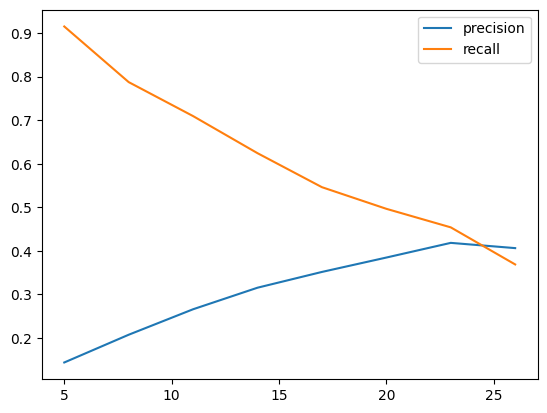

In [26]:
plt.plot(threshold_list, precision_list, label="precision")
plt.plot(threshold_list, recall_list, label="recall")
plt.legend()
plt.show()

[134 152 231 232]
[152, 190]
Result:        P=0.250 R=0.500 F1=0.333 IoU=0.200 (TP=1, FP=3, FN=1)


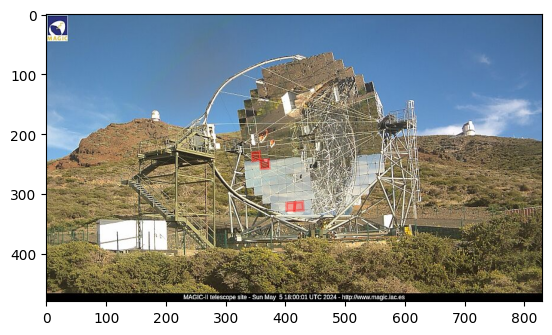

[  9  33  52  85 101 102 118 119 120 121 142 150 151 152 153 154 155 169
 170 171 172 184 188 189 190 193 217 221 231 232]
[150, 151, 152, 153, 154, 168, 169, 170, 171, 172, 189, 190, 191, 204, 206, 207, 221, 222, 235, 236, 246]
Result:        P=0.400 R=0.571 F1=0.471 IoU=0.308 (TP=12, FP=18, FN=9)


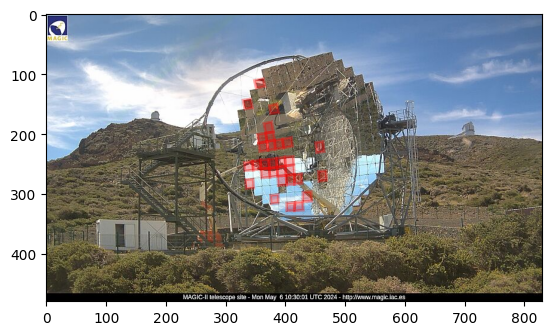

[ 85 101 102 118 119 121 135 154 188 189 190]
[152, 176, 189, 190, 191, 192, 193, 204, 209]
Result:        P=0.182 R=0.222 F1=0.200 IoU=0.111 (TP=2, FP=9, FN=7)


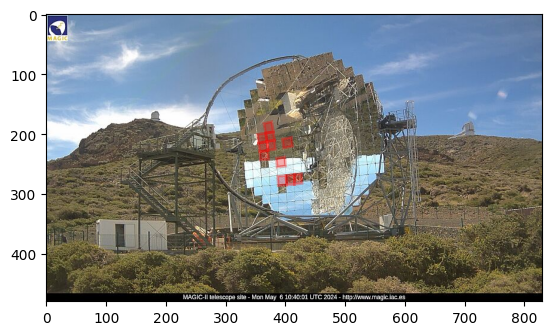

[ 85 101 102 118 119 120 121 135 150 151 153 154 155 156 169 171 172 173
 184 188 189 190 191 201 204 216 227]
[152, 176, 189, 190, 191, 192, 193, 204, 209]
Result:        P=0.148 R=0.444 F1=0.222 IoU=0.125 (TP=4, FP=23, FN=5)


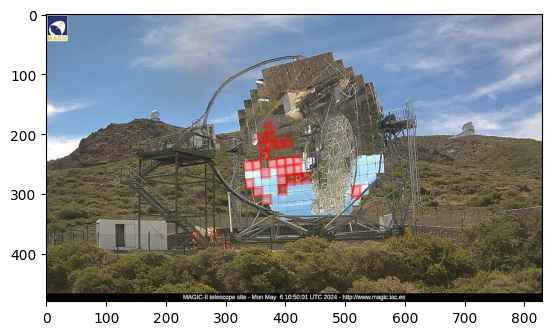

[101 119 121 135 152 188 189 190 193 217 231 232]
[119, 121, 135, 152, 176, 189, 190, 191, 192, 193, 204, 209]
Result:        P=0.583 R=0.583 F1=0.583 IoU=0.412 (TP=7, FP=5, FN=5)


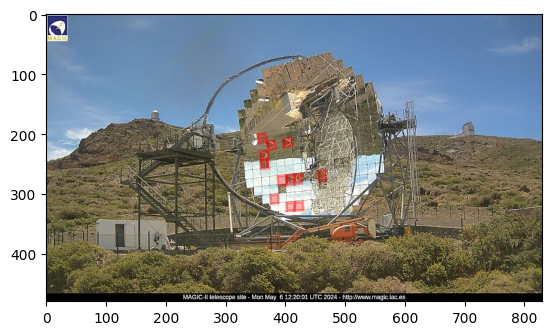

[101 119 121 152 153 154 172 184 185 186 187 188 189 190 201 202 203 205
 206 207 216 217 218 219 220 221 227 229 230 231 232 233 243]
[119, 121, 135, 152, 176, 189, 190, 191, 192, 193, 204, 209]
Result:        P=0.152 R=0.417 F1=0.222 IoU=0.125 (TP=5, FP=28, FN=7)


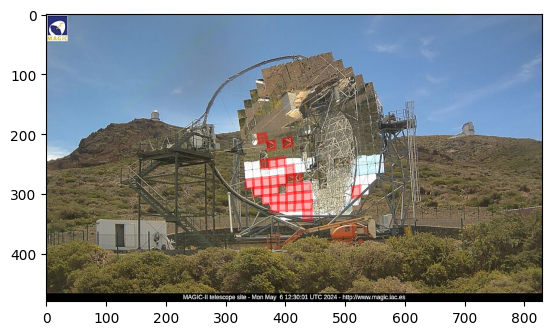

[ 84 101 119 121 135 152 188 189 190 193 231]
[119, 121, 135, 152, 176, 189, 190, 191, 192, 193, 204, 209]
Result:        P=0.636 R=0.583 F1=0.609 IoU=0.438 (TP=7, FP=4, FN=5)


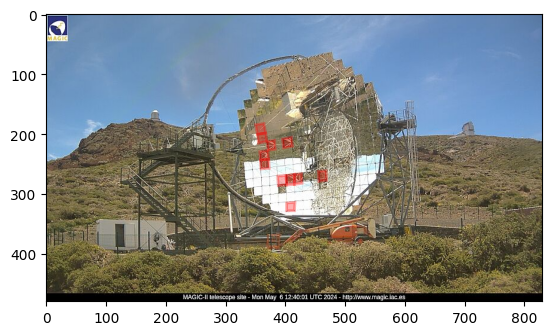

[101 119 142 152 176 179 190 193]
[119, 152, 176, 179, 190, 193, 209]
Result:        P=0.750 R=0.857 F1=0.800 IoU=0.667 (TP=6, FP=2, FN=1)


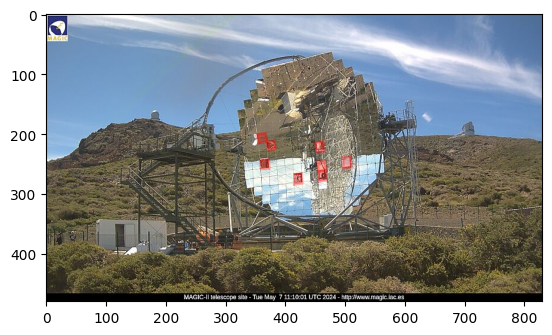

[101 142 152 176 179 190 193]
[152, 176, 179, 190, 209]
Result:        P=0.571 R=0.800 F1=0.667 IoU=0.500 (TP=4, FP=3, FN=1)


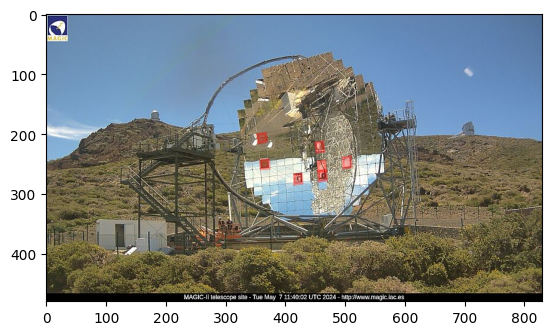

[101 119 152 179 190 193 216]
[152, 176, 179, 190, 209, 216]
Result:        P=0.571 R=0.667 F1=0.615 IoU=0.444 (TP=4, FP=3, FN=2)


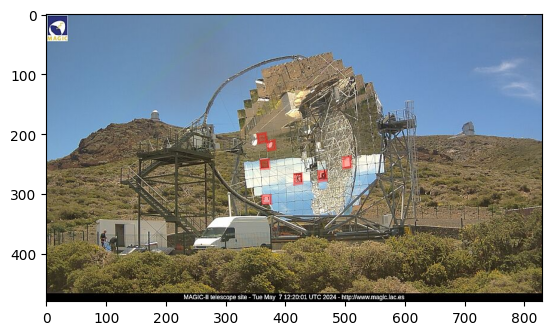

True positive: %d: 52
False positive: %d: 98
False negative: %d: 43
Summary precision: %.3f 0.3466666666666667
Summary recall: %.3f 0.5473684210526316


In [14]:
tp_sum = 0
fp_sum = 0
fn_sum = 0

for i, obj in enumerate(json_metadata_list[:10]):
    file_name = obj['file']
    img_path = IMG_DIR_PATH / file_name
    X_new = proces_one_img(img_path, mirror_extractor)
    R_new = robust_z(X_new[None, ...], axis=1)[0]
    Z_new = R_new - b["mu"]
    d2 = lw.mahalanobis(Z_new)
    d2 = lw.mahalanobis(Z_new)
    score = d2 / b["d2_med"]
    outliers_mirrors = np.where(score > 2.5*b["threshold"])[0]

    ground_truth = obj["marked_mirrors"]
    print(outliers_mirrors)
    print(ground_truth)
    metrics = compute_metrics(outliers_mirrors, ground_truth)
    print(f"Result:        {metrics.summary}")

    points = [mirror_extractor.get_point_coords(m_id) for m_id in outliers_mirrors]
    fig, ax = plt.subplots()
    mark_mirrors_on_img(img_path, points, "red", ax)
    plt.show()

    tp_sum += metrics.tp
    fp_sum += metrics.fp
    fn_sum += metrics.fn

precision = tp_sum / (tp_sum + fp_sum)
recall = tp_sum / (tp_sum + fn_sum)
print(f"True positive: %d: {tp_sum}")
print(f"False positive: %d: {fp_sum}")
print(f"False negative: %d: {fn_sum}")
print("Summary precision: %.3f", precision)
print("Summary recall: %.3f", recall)


In [ ]:
metrics.tn

In [7]:
obj["marked_mirrors"]

[152, 190]